# Black Sigatoka XGBoost

A compact training and comparison notebook. Only the approved training and validation partitions are used.

## 1. Import Libraries



In [1]:
from pathlib import Path
import json, sys
import joblib, matplotlib.pyplot as plt, numpy as np, pandas as pd, seaborn as sns
from IPython.display import display
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, classification_report, confusion_matrix)
from xgboost import XGBRegressor
import xgboost

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from black_sigatoka_preprocessing import (
    FEATURES, TARGET, load_and_validate_datasets, prepare_model_inputs,
    risk_score_to_category,
)


## 2. Load Dataset



In [2]:
# Load the dataset
frames, split_summaries = load_and_validate_datasets(
    PROJECT_ROOT, splits=("train", "validation")
)
assert set(frames) == {"train", "validation"}
assert len(frames["train"]) == 4501 and len(frames["validation"]) == 937
display(pd.DataFrame(split_summaries).T)


,split,source_file,rows,columns,schema_consistent,selected_missing_values,selected_nonfinite_values,risk_score_min,risk_score_max,risk_category_mismatches,input_shape,target_shape
train,train,datasets/black_sigatoka/revised_splits/BS_SOUR...,4501,25,True,0,0,0.0,99.995,0,4501 x 3,4501
validation,validation,datasets/black_sigatoka/revised_splits/BS_SOUR...,937,25,True,0,0,0.0,99.9939,0,937 x 3,937


## 3. Select Features and Target



In [3]:
# Select approved inputs and target
model_inputs, targets = prepare_model_inputs(frames, splits=("train", "validation"))
X_train, X_val = model_inputs["train"], model_inputs["validation"]
y_train, y_val = targets["train"], targets["validation"]
assert X_train.columns.tolist() == FEATURES
assert X_val.columns.tolist() == FEATURES
print("Features:", FEATURES)
print("Target:", TARGET)
print("Train:", X_train.shape, "Validation:", X_val.shape)


Features: ['air_temp_c', 'estimated_leaf_wet', 'consecutive_wetness_hours']
Target: risk_score
Train: (4501, 3) Validation: (937, 3)


## 4. Train XGBoost



In [4]:
# Train XGBoost
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
)
xgb_model.fit(X_train, y_train)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,1.0
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## 5. Predict Risk Scores



In [5]:
# Predict risk scores
train_pred = xgb_model.predict(X_train)
val_pred = xgb_model.predict(X_val)


## 6. Model Evaluation

Lower MAE and RMSE are better. Higher R? is generally better. Metrics use raw predictions on the original 0?100 score scale.

In [6]:
# Calculate prediction errors
def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }

baseline_train_metrics = regression_metrics(y_train, train_pred)
baseline_val_metrics = regression_metrics(y_val, val_pred)
baseline_metric_table = pd.DataFrame(
    {"Training": baseline_train_metrics, "Validation": baseline_val_metrics}
)
display(baseline_metric_table)


,Training,Validation
MAE,0.589046,0.676068
RMSE,0.896104,1.128364
R2,0.999423,0.999137


## 7. Hyperparameter Tuning

Compare nine predefined settings, including the initial model. Candidates fit on training data and are selected by validation MAE, with RMSE as the tie-breaker.

In [7]:
baseline_params = {
    "n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
    "min_child_weight": 1,
}
candidate_settings = [
    baseline_params,
    {"n_estimators": 200, "max_depth": 3, "learning_rate": 0.05, "min_child_weight": 1},
    {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.05, "min_child_weight": 1},
    {"n_estimators": 300, "max_depth": 4, "learning_rate": 0.05, "min_child_weight": 1},
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.03, "min_child_weight": 1},
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.10, "min_child_weight": 1},
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05, "min_child_weight": 3},
    {"n_estimators": 300, "max_depth": 5, "learning_rate": 0.03, "min_child_weight": 1},
    {"n_estimators": 300, "max_depth": 3, "learning_rate": 0.10, "min_child_weight": 3},
]
fixed_params = {
    "objective": "reg:squarederror", "subsample": 1.0,
    "colsample_bytree": 1.0, "random_state": 42, "n_jobs": -1,
    "tree_method": "hist",
}
tuning_rows = []
fitted_candidates = []
for i, params in enumerate(candidate_settings):
    # Reuse the already fitted baseline candidate
    if i == 0:
        candidate = xgb_model
    else:
        candidate = XGBRegressor(**fixed_params, **params)
        candidate.fit(X_train, y_train)
    candidate_train_pred = candidate.predict(X_train)
    candidate_val_pred = candidate.predict(X_val)
    train_scores = regression_metrics(y_train, candidate_train_pred)
    val_scores = regression_metrics(y_val, candidate_val_pred)
    tuning_rows.append({
        **params,
        "validation_mae": val_scores["MAE"],
        "validation_rmse": val_scores["RMSE"],
        "validation_r2": val_scores["R2"],
        "initial_baseline": i == 0,
    })
    fitted_candidates.append((candidate, params, candidate_train_pred, candidate_val_pred, train_scores, val_scores))

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    ["validation_mae", "validation_rmse"]
).reset_index(drop=True)
best_row = tuning_results.iloc[0]
best_index = next(i for i, row in enumerate(tuning_rows)
                  if row["validation_mae"] == best_row["validation_mae"]
                  and row["validation_rmse"] == best_row["validation_rmse"])
best_model, best_params, train_pred, val_pred, train_metrics, val_metrics = fitted_candidates[best_index]
print("Best settings:", best_params)
print("Selected model:", "Initial baseline" if best_index == 0 else "Tuned XGBoost")
display(tuning_results)


Best settings: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05, 'min_child_weight': 1}
Selected model: Tuned XGBoost


,n_estimators,max_depth,learning_rate,min_child_weight,validation_mae,validation_rmse,validation_r2,initial_baseline
0,200,5,0.05,1,0.497516,0.882316,0.999472,False
1,300,5,0.03,1,0.500623,0.883393,0.999471,False
2,200,4,0.10,1,0.545080,0.944494,0.999395,False
3,300,4,0.05,1,0.598073,1.003371,0.999317,False
4,200,4,0.05,1,0.676068,1.128364,0.999137,True
5,200,4,0.05,3,0.689209,1.150383,0.999103,False
6,300,3,0.10,3,0.752121,1.195533,0.999031,False
7,200,4,0.03,1,0.828697,1.338037,0.998786,False
8,200,3,0.05,1,1.354859,2.028514,0.997210,False


## 8. Check Overfitting

Compare training and validation metrics. A higher validation error alone does not prove overfitting.

In [8]:
overfit_table = pd.DataFrame({
    "Training": train_metrics,
    "Validation": val_metrics,
})
overfit_table["Validation - Training"] = overfit_table["Validation"] - overfit_table["Training"]
display(overfit_table)


,Training,Validation,Validation - Training
MAE,0.365605,0.497516,0.131912
RMSE,0.589470,0.882316,0.292845
R2,0.999750,0.999472,-0.000278


## 9. Risk-Level Evaluation

Raw regression predictions stay unchanged. For category evaluation only, a separate copy is bounded to 0?100 before applying the existing category rules.

In [9]:
CATEGORY_ORDER = ["No Risk", "Low", "Moderate", "High"]
raw_val_pred = val_pred.copy()
out_of_range = (raw_val_pred < 0) | (raw_val_pred > 100)
out_of_range_count = int(out_of_range.sum())
if out_of_range_count:
    print("Out-of-range predictions:", out_of_range_count,
          "min:", float(raw_val_pred.min()), "max:", float(raw_val_pred.max()))
else:
    print("Out-of-range predictions: 0")

# Clip a separate prediction array only for category assignment
bounded_val_pred = np.clip(raw_val_pred, 0, 100)
actual_categories = y_val.map(risk_score_to_category)
predicted_categories = pd.Series(bounded_val_pred, index=y_val.index).map(risk_score_to_category)
category_accuracy = accuracy_score(actual_categories, predicted_categories)
classification_table = pd.DataFrame(classification_report(
    actual_categories,
    predicted_categories,
    labels=CATEGORY_ORDER,
    target_names=CATEGORY_ORDER,
    output_dict=True,
    zero_division=0,
)).T
category_summary = classification_table.loc[
    CATEGORY_ORDER + ["macro avg", "weighted avg"],
    ["precision", "recall", "f1-score", "support"],
].rename(index={"macro avg": "Macro Average", "weighted avg": "Weighted Average"})
category_summary.index.name = "Risk Level"
category_summary = category_summary.rename(columns={"f1-score": "F1-score"})
print("Validation category accuracy:", category_accuracy)
display(category_summary)


Out-of-range predictions: 252 min: -0.067133828997612 max: 100.2566146850586
Validation category accuracy: 0.8996798292422625


,precision,recall,F1-score,support
Risk Level,,,,
No Risk,1.000000,0.724458,0.840215,323.0
Low,0.597345,0.992647,0.745856,136.0
Moderate,0.995690,0.982979,0.989293,235.0
High,0.991837,1.000000,0.995902,243.0
Macro Average,0.896218,0.925021,0.892817,937.0
Weighted Average,0.938359,0.899680,0.904284,937.0


## 10. Confusion Matrix



In [10]:
category_cm = confusion_matrix(actual_categories, predicted_categories, labels=CATEGORY_ORDER)
display(pd.DataFrame(category_cm, index=CATEGORY_ORDER, columns=CATEGORY_ORDER))


,No Risk,Low,Moderate,High
No Risk,234,89,0,0
Low,0,135,1,0
Moderate,0,2,231,2
High,0,0,0,243


## 11. Prediction Graphs



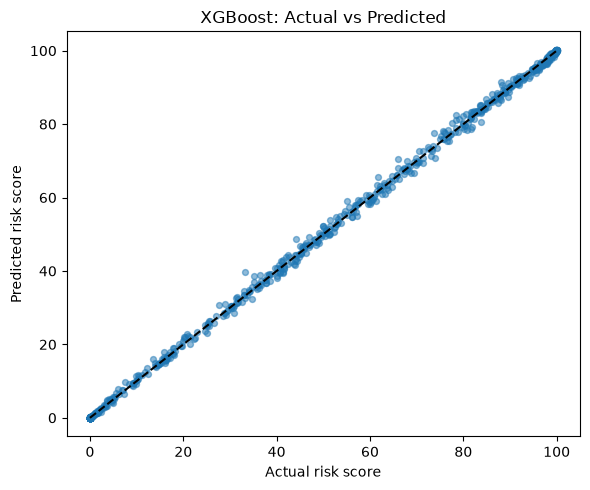

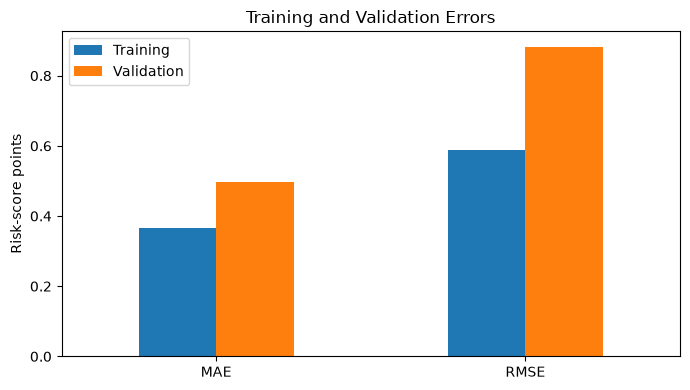

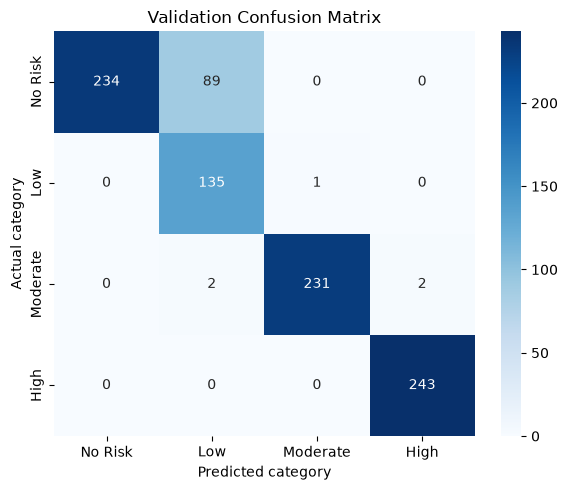

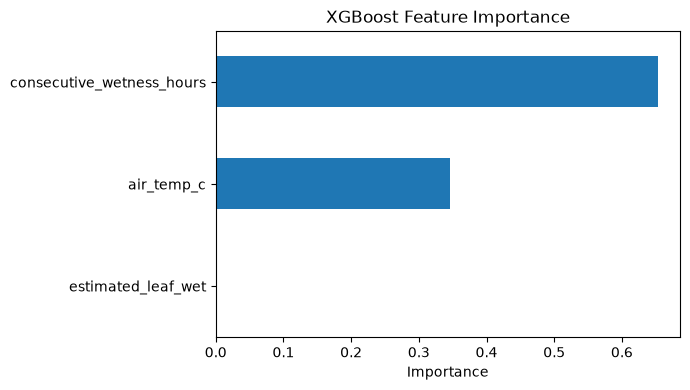

In [11]:
xgb_report_dir = PROJECT_ROOT / "reports" / "black_sigatoka" / "xgboost"
xgb_report_dir.mkdir(parents=True, exist_ok=True)

# Actual versus predicted validation scores
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_val, raw_val_pred, alpha=0.5, s=18)
ax.plot([0, 100], [0, 100], "--", color="black")
ax.set(xlabel="Actual risk score", ylabel="Predicted risk score", title="XGBoost: Actual vs Predicted")
fig.tight_layout()
fig.savefig(xgb_report_dir / "actual_vs_predicted.png", dpi=150)
plt.show()

# Training versus validation errors
fig, ax = plt.subplots(figsize=(7, 4))
error_plot = pd.DataFrame({"Training": [train_metrics["MAE"], train_metrics["RMSE"]],
                           "Validation": [val_metrics["MAE"], val_metrics["RMSE"]]},
                          index=["MAE", "RMSE"])
error_plot.plot(kind="bar", ax=ax)
ax.set_ylabel("Risk-score points")
ax.set_title("Training and Validation Errors")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(xgb_report_dir / "training_validation_errors.png", dpi=150)
plt.show()

# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(category_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CATEGORY_ORDER, yticklabels=CATEGORY_ORDER, ax=ax)
ax.set(xlabel="Predicted category", ylabel="Actual category", title="Validation Confusion Matrix")
fig.tight_layout()
fig.savefig(xgb_report_dir / "confusion_matrix.png", dpi=150)
plt.show()

# Feature importance
importance = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
importance.plot(kind="barh", ax=ax, title="XGBoost Feature Importance")
ax.set_xlabel("Importance")
fig.tight_layout()
fig.savefig(xgb_report_dir / "feature_importance.png", dpi=150)
plt.show()


## 12. Compare Random Forest and XGBoost



In [12]:
# Compare with Random Forest using its saved full-precision reports
rf_report_dir = PROJECT_ROOT / "reports" / "black_sigatoka" / "random_forest"
rf_comparison = pd.read_csv(rf_report_dir / "model_comparison.csv")
rf_row = rf_comparison.loc[rf_comparison["selected"]].iloc[0]
rf_classification = pd.read_csv(rf_report_dir / "validation_classification_report.csv").set_index("category")
rf_accuracy = float(rf_classification.loc["accuracy", "f1_score"])
rf_macro_f1 = float(rf_classification.loc["macro avg", "f1_score"])
xgb_macro_f1 = float(classification_table.loc["macro avg", "f1-score"])
comparison_table = pd.DataFrame([
    {"Metric": "Validation MAE", "Random Forest": rf_row["validation_mae"], "XGBoost": val_metrics["MAE"]},
    {"Metric": "Validation RMSE", "Random Forest": rf_row["validation_rmse"], "XGBoost": val_metrics["RMSE"]},
    {"Metric": "Validation R-squared", "Random Forest": rf_row["validation_r2"], "XGBoost": val_metrics["R2"]},
    {"Metric": "Category accuracy", "Random Forest": rf_accuracy, "XGBoost": category_accuracy},
    {"Metric": "Macro F1-score", "Random Forest": rf_macro_f1, "XGBoost": xgb_macro_f1},
])
display(comparison_table)


,Metric,Random Forest,XGBoost
0,Validation MAE,0.363315,0.497516
1,Validation RMSE,0.754338,0.882316
2,Validation R-squared,0.999614,0.999472
3,Category accuracy,0.994664,0.899680
4,Macro F1-score,0.993559,0.892817


## 13. Save Model



In [13]:
model_dir = PROJECT_ROOT / "Models" / "black_sigatoka" / "xgboost"
model_dir.mkdir(parents=True, exist_ok=True)
model_path = model_dir / "xgboost_model.joblib"
metadata_path = model_dir / "model_metadata.json"

# Save the selected model
joblib.dump(best_model, model_path)
reloaded_model = joblib.load(model_path)
reloaded_pred = reloaded_model.predict(X_val)
np.testing.assert_allclose(reloaded_pred, raw_val_pred, rtol=0, atol=1e-12)
print("Saved and reloaded model predictions match.")

metadata = {
    "model_type": "XGBoost Regressor",
    "selected_parameters": {**fixed_params, **best_params},
    "features": FEATURES,
    "target": TARGET,
    "training_metrics": train_metrics,
    "validation_metrics": val_metrics,
    "category_metrics": {
        "accuracy": category_accuracy,
        "macro_precision": float(classification_table.loc["macro avg", "precision"]),
        "macro_recall": float(classification_table.loc["macro avg", "recall"]),
        "macro_f1": xgb_macro_f1,
        "weighted_f1": float(classification_table.loc["weighted avg", "f1-score"]),
        "per_category_f1": {level: float(classification_table.loc[level, "f1-score"]) for level in CATEGORY_ORDER},
    },
    "risk_category_thresholds": {
        "No Risk": "score == 0", "Low": "0 < score < 25",
        "Moderate": "25 <= score < 75", "High": "75 <= score <= 100",
    },
    "out_of_range_validation_predictions": {
        "count": out_of_range_count, "minimum": float(raw_val_pred.min()),
        "maximum": float(raw_val_pred.max()),
    },
    "library_versions": {
        "xgboost": xgboost.__version__, "numpy": np.__version__, "pandas": pd.__version__,
        "scikit_learn": __import__("sklearn").__version__, "joblib": joblib.__version__,
    },
    "dataset_files": {
        "train": "datasets/black_sigatoka/revised_splits/BS_SOURCE_TIME_train.csv",
        "validation": "datasets/black_sigatoka/revised_splits/BS_SOURCE_TIME_validation.csv",
        "test_dataset_loaded": False,
    },
    "limitations": [
        "Risk scores are mathematically generated synthetic labels, not verified Black Sigatoka infections.",
        "The upstream label-generating function is unavailable.",
        "Six identical three-feature combinations have small score differences.",
        "NASA-derived weather differs from the synthetic training distribution.",
        "This is current environmental risk scoring, not validated future disease forecasting.",
    ],
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")


Saved and reloaded model predictions match.


2205

## 14. Final Results



In [14]:
# Save readable experiment results
metrics_table = pd.DataFrame([
    {"model": "Selected XGBoost", "split": split, **scores}
    for split, scores in [("train", train_metrics), ("validation", val_metrics)]
])
metrics_table.to_csv(xgb_report_dir / "model_metrics.csv", index=False)
tuning_results.to_csv(xgb_report_dir / "tuning_results.csv", index=False)

validation_predictions = frames["validation"][FEATURES + [TARGET, "risk_level"]].copy()
validation_predictions["raw_predicted_risk_score"] = raw_val_pred
validation_predictions["bounded_category_prediction"] = bounded_val_pred
validation_predictions["predicted_risk_level"] = predicted_categories.to_numpy()
validation_predictions.to_csv(xgb_report_dir / "validation_predictions.csv", index=False)

saved_classification = category_summary.reset_index().rename(columns={"Risk Level": "category"})
saved_classification.to_csv(xgb_report_dir / "validation_classification_report.csv", index=False)
pd.DataFrame(category_cm, index=CATEGORY_ORDER, columns=CATEGORY_ORDER).rename_axis("actual_category").to_csv(
    xgb_report_dir / "validation_confusion_matrix.csv"
)
comparison_table.to_csv(xgb_report_dir / "rf_vs_xgboost_comparison.csv", index=False)
preferred_model_name = "Random Forest" if rf_row["validation_mae"] <= val_metrics["MAE"] else "XGBoost"
print("Preferred model by validation MAE:", preferred_model_name)

# Show a few validation predictions
examples = validation_predictions.iloc[:5][FEATURES + [TARGET, "risk_level", "raw_predicted_risk_score", "predicted_risk_level"]].copy()
examples = examples.rename(columns={
    "air_temp_c": "Air temperature (C)", "estimated_leaf_wet": "Estimated leaf wetness",
    "consecutive_wetness_hours": "Consecutive wetness hours", TARGET: "Actual risk score",
    "risk_level": "Actual risk category", "raw_predicted_risk_score": "Predicted risk score",
    "predicted_risk_level": "Predicted risk category",
})
display(examples)

report_text = f"""# XGBoost Training Report

## Dataset and features
- Training records: {len(X_train)}; validation records: {len(X_val)}.
- Test data was not loaded or evaluated.
- Features: {", ".join(FEATURES)}; target: `{TARGET}`.

## Model settings
- Initial baseline: {json.dumps(baseline_params)}.
- Selected settings: {json.dumps(best_params)}.
- Candidates compared: {len(candidate_settings)}; selection used validation MAE, then RMSE.

## Regression metrics
{metrics_table.to_string(index=False)}

## Validation categories
- Accuracy: {category_accuracy:.6f}; macro precision: {classification_table.loc["macro avg", "precision"]:.6f}; macro recall: {classification_table.loc["macro avg", "recall"]:.6f}.
- Macro F1: {xgb_macro_f1:.6f}; weighted F1: {classification_table.loc["weighted avg", "f1-score"]:.6f}.
- Out-of-range raw predictions: {out_of_range_count} (minimum {raw_val_pred.min():.6f}, maximum {raw_val_pred.max():.6f}). Category predictions use a separate 0 to 100 bounded copy.

## Random Forest comparison
{comparison_table.to_string(index=False)}

Preferred model by validation MAE: {preferred_model_name}. MAE is the primary comparison metric; RMSE breaks ties. The validation set was also used for tuning, so comparison scores are preliminary.

## Overfitting check
Training MAE/RMSE: {train_metrics["MAE"]:.6f} / {train_metrics["RMSE"]:.6f}; validation MAE/RMSE: {val_metrics["MAE"]:.6f} / {val_metrics["RMSE"]:.6f}. Interpret the gap as a diagnostic, not proof by itself.

## Confusion matrix
{pd.DataFrame(category_cm, index=CATEGORY_ORDER, columns=CATEGORY_ORDER).to_string()}

## Scientific limitations
Risk scores are mathematically generated synthetic labels, not confirmed infections; the upstream label generator is unavailable. Six identical feature combinations have small score differences. NASA-derived weather differs from this synthetic training distribution. This experiment estimates current environmental risk scores, not validated future disease forecasts. High R-squared or F1 does not establish plantation disease-prediction accuracy.
"""
(xgb_report_dir / "XGBoost_Training_Report.md").write_text(report_text, encoding="utf-8")
print("Saved XGBoost model, metadata, metrics, predictions, comparison, plots, and report to:", xgb_report_dir)


Preferred model by validation MAE: Random Forest


,Air temperature (C),Estimated leaf wetness,Consecutive wetness hours,Actual risk score,Actual risk category,Predicted risk score,Predicted risk category
0,30.865,0,0,0.0000,No Risk,-0.020413,No Risk
1,22.044,1,92,81.6215,High,83.187943,High
2,28.262,1,69,96.6965,High,96.998383,High
3,33.120,0,0,0.0000,No Risk,-0.020413,No Risk
4,22.960,1,31,31.4656,Moderate,33.031048,Moderate


Saved XGBoost model, metadata, metrics, predictions, comparison, plots, and report to: C:\Users\HP\Desktop\ML training\reports\black_sigatoka\xgboost
